# **LINEAR REGRESSION**

* Regression models helps to look at the relationship between a dependent variable (response variable) and a set of independent variables (explanatory variables).

* OLS stands for ordinary least squares. OLS is heavily used in econometrics—a branch of economics where statistical methods are used to find the insights in economic data.

* The simplest linear regression algorithm assumes that the relationship between an independent variable (x) and dependent variable (y) is of the following form: y = mx + c, which is the equation of a line.

* In line with that, OLS is an estimator in which the values of m and c (from the above equation) are chosen in such a way as to minimize the sum of the squares of the differences between the observed dependent variable and predicted dependent variable. That’s why it’s named ordinary least squares.

* OLS is a technique for estimating the parameters (coefficients) of a linear regression model by minimizing the sum of the squared differences between the observed and predicted values of the dependent variable.

* Also, it should be noted that when the sum of the squares of the differences is minimum, the loss is also minimum—hence the prediction is better.


**1. Import Libraries**

In [1]:

# Importing the necessary Python Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols




**2. Import the data and explore it**

In [2]:
# Importing the heart data from the CSV file
car_data = pd.read_csv('auto.csv')
car_data.head()   # List the first 5 rows of tabular data


,mpg,cylinders,displacement,housepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino


In [ ]:
# You can also get it directly from the web and assigning the column names
# car_data = pd.read_table("https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data", sep="\s+", \
#                         names=['mpg','cylinders','displacement','horsepower','weight','acceleration','model year','origin','car name'])
# car_data.head() #To view the top 5 rows of the data

In [3]:
car_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   housepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


In [4]:
#Gives a descriptive statistics of the numeric columns
car_data.describe()

,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


In [5]:
# Getting the unique values of columns
car_data['cylinders'].unique()

array([8, 4, 6, 3, 5])

**3. Bivariate Linear Regression**: Regression with a single explanatory variable.

Text(0.5, 1.0, 'Bar chart of car data')

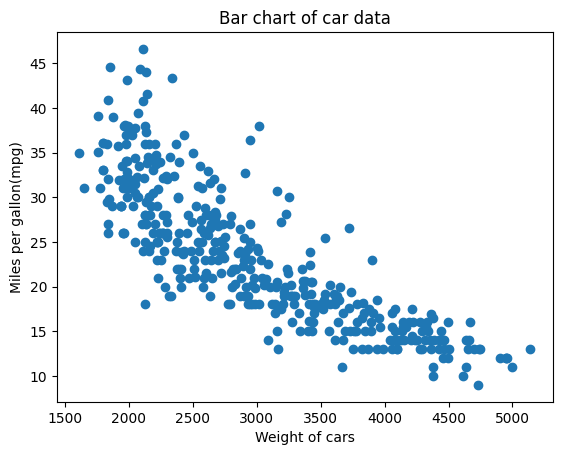

In [6]:
# Explore the relationship between two numeric variables
plt.scatter(car_data['weight'], car_data['mpg'])
plt.xlabel('Weight of cars')
plt.ylabel('Miles per gallon(mpg)')
plt.title('Bar chart of car data')

*3.1 Bivariate with numeric explanatory variable*

In [7]:
# Run the regression and assign it to a name 'car_regression'.
car_regression = ols('mpg ~ weight', data = car_data).fit()

In [15]:
#Print out the result of the regression
print(car_regression.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.692
Model:                            OLS   Adj. R-squared:                  0.691
Method:                 Least Squares   F-statistic:                     888.9
Date:                Tue, 03 Oct 2023   Prob (F-statistic):          2.97e-103
Time:                        14:24:34   Log-Likelihood:                -1148.4
No. Observations:                 398   AIC:                             2301.
Df Residuals:                     396   BIC:                             2309.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     46.3174      0.795     58.243      0.0

This means that when the weight of a car increase by 1 unit, the mpg reduces by 0.0077 unit. That is, on the average, when the weight of a car increases by 1 pounds, it leads to 0.0077 reduction in the mpg.

*3.2 Bivariate with categorical explanatory variable*

In [9]:
# Here we want to create a new categorical variable called 'cyl_str' from the cylinder column
car_data['cyl_str'] = car_data['cylinders'].astype(str)

In [10]:
# Check out the new column
car_data.columns
car_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   housepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
 9   cyl_str       398 non-null    object 
dtypes: float64(3), int64(4), object(3)
memory usage: 31.2+ KB


In [11]:
# For clean bar chart, let's sort the values of the new column from the least to the greatest.
car_sort = car_data.sort_values('cyl_str')

In [12]:
# Getting the unique values of columns
car_sort['cyl_str'].unique()

array(['3', '4', '5', '6', '8'], dtype=object)

Text(0.5, 1.0, 'Bar chart of car data')

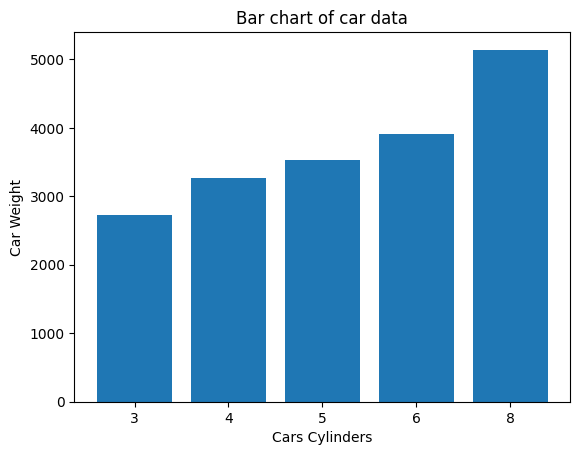

In [13]:
#Plot the bar graph
plt.bar(car_sort['cyl_str'], car_sort['weight'])
plt.xlabel('Cars Cylinders')
plt.ylabel('Car Weight')
plt.title('Bar chart of car data')

In [16]:
# Run the regression with one explanatory categorical variable
car_regression = ols('weight ~ cyl_str', data = car_data).fit()

In [17]:
#Print out the result
print(car_regression.summary())

                            OLS Regression Results                            
Dep. Variable:                 weight   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.806
Method:                 Least Squares   F-statistic:                     413.7
Date:                Tue, 03 Oct 2023   Prob (F-statistic):          2.12e-139
Time:                        14:24:49   Log-Likelihood:                -2918.8
No. Observations:                 398   AIC:                             5848.
Df Residuals:                     393   BIC:                             5868.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept     2398.5000    186.424     12.866   

This means that cars with 4 cylinders, on the average are **90.3725** pounds less weightier than cars with 3 cylinders. Also, cars with 5 cylinders are on the average **704.8333** pounds weightier than cars with 3 cylinders.

**4. Multiple Linear Regression**: Regression with more than one explanatory variable.

*4.1 Multiple linear regression with two numeric explanatory variables*

In [18]:
# In this code line, we are looking at the effects of car weight and number of cylinders on miles per gallon(mpg)
car_multi_reg = ols('mpg ~ weight + cylinders', data = car_data).fit()

In [19]:
#Print out the result
print(car_multi_reg.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.696
Model:                            OLS   Adj. R-squared:                  0.695
Method:                 Least Squares   F-statistic:                     453.0
Date:                Tue, 03 Oct 2023   Prob (F-statistic):          5.68e-103
Time:                        14:33:07   Log-Likelihood:                -1145.4
No. Observations:                 398   AIC:                             2297.
Df Residuals:                     395   BIC:                             2309.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     46.3937      0.791     58.660      0.0

The signs of the coefficient shows the direction of the relationship between the explanatory variable and the response variable. Here it shows that there is an inverse relationship between the weight of cars and miles per gallon (mpg). The same also goes for the relationship between car cylinders and mpg.


The result means that for a unit increase in weight (i.e, when the weight of the car increase by 1 pound), the miles per galon (mpg) decreases by **0.0064**, when the effects of cylinder is held constant. Also, when the value of the car cylinder increases by one unit, the mles per gallon (mpg) will decrease by **0.7025**, when the effects of weight is held constant.



**Question:** From the result, what happens to the value of mpg when the weight of a car decreases by 1000 pounds?

*4.2 Multiple linear regression with one numeric and one categorical explanatory variables*

In [20]:
# Looking atthe effects of weight and cylinder (categorical) on miles per gallon (mpg)
car_multi_reg = ols('mpg ~ weight + cyl_str', data = car_data).fit()

In [21]:
#Print out the result
print(car_multi_reg.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.724
Model:                            OLS   Adj. R-squared:                  0.720
Method:                 Least Squares   F-statistic:                     205.4
Date:                Tue, 03 Oct 2023   Prob (F-statistic):          3.98e-107
Time:                        14:33:16   Log-Likelihood:                -1126.6
No. Observations:                 398   AIC:                             2265.
Df Residuals:                     392   BIC:                             2289.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       35.4148      2.464     14.372   

This means that cars with 4 cylinders, on the average covers  **8.1767** more mpg than cars with 3 cylinders, when the effects of weight is held constant. Also, when car weight increases by 1 pound, the mpg decreases by **0.0062**, holding the effects of car cylinders constant.